# Base Modeling

Este notebook parte del **dataset final** de Data Preparation (`dataset_final.parquet`, guardado en la última celda de `DataPreparation.ipynb`).


### 1. Conectar con Google Drive e importar librerías

In [93]:
%load_ext autoreload
%autoreload 2
import os
import numpy as np
import pandas as pd
from sklearn.utils.class_weight import compute_class_weight
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [94]:
if IN_COLAB:
  print("Mount Colab")
  from google.colab import drive
  drive.mount('/content/drive')
  !rm -rf vms
  RUTA_DATOS = "/content/drive/My Drive/Datos/Procesado"
else:
  print("Running local")
  RUTA_DATOS = Path.cwd() / ".." / ".." / "data"
  print(RUTA_DATOS)

Running local
c:\Users\Santiago\Documents\Personal\IA\VMS-prediction\notebooks\modeling\..\..\data


In [95]:
if IN_COLAB:  
  !git clone https://github.com/kamimartinez/VMS-prediction.git vms
  def change_branch(branch):
    !git -C vms checkout {branch}
  # change_branch("feat/lstm")
  sys.path.append(os.path.abspath("vms/notebooks"))

In [96]:
if IN_COLAB:
  !ls vms/notebooks

### 2. Cargar el dataset final
Se lee desde `Datos/Procesado`. Si no existe, primero hay que ejecutar `DataPreparation.ipynb` completo.

In [97]:
def load_dataset(file="dataset_final_serie_tiempo.parquet"):
  dataset_final = pd.read_parquet(os.path.join(RUTA_DATOS, file))
  dataset_final["bloque_tiempo"] = pd.to_datetime(dataset_final["bloque_tiempo"])
  dataset_final = dataset_final.sort_values(["bloque_tiempo", "ms"]).reset_index(drop=True)

  print(f"dataset_final: {len(dataset_final):,} bloques x {dataset_final.shape[1]} columnas")
  print(list(dataset_final.columns))
  return dataset_final

### 3. Parámetros

In [98]:
TARGET = "pct_posible_cola"
N_FOLDS = 5

# Normalización de datos

In [99]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

TARGET = "pct_posible_cola"

df = load_dataset()
df = df.sort_values(["ms", "bloque_tiempo"]).reset_index(drop=True)

g = df.groupby("ms")
contiguo = (df["bloque_tiempo"] - g["bloque_tiempo"].shift(1)) == pd.Timedelta("30min")

COLS_ORDENIO = [
    "total_ordenios",
    "duracion_total_min",
    "pct_ocupacion_robot",
    "hubo_ordenios",
]
cols_lag = [c for c in COLS_ORDENIO if c in df.columns]

for c in cols_lag:
    df[f"{c}_anterior"] = g[c].shift(1).where(contiguo)

df["pct_cola_anterior"] = g[TARGET].shift(1).where(contiguo)

df["cola"] = (df[TARGET] > 0.5).astype("float32")
df = df.sort_values(["bloque_tiempo"])

df_clean = df.drop(columns=cols_lag).dropna(subset=["pct_cola_anterior"]).copy()

df_clean = pd.get_dummies(df_clean, columns=["ms", "temporada"], dtype="float32")

DROP_COLUMNS = [TARGET, "bloque_tiempo", "cola", "vacas_activas_dia", "produccion_promedio", "sin_etapa"]
y_all = df_clean["cola"].values
X = df_clean.drop(columns=DROP_COLUMNS)
print(X.columns)

dummies = [c for c in X.columns if c.startswith(("ms_", "temporada_"))]
categoricas = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()
numericas = [
    c
    for c in X.select_dtypes(include="number").columns
    if c not in dummies and c != "cola"
]
binarias = dummies

num_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="constant", fill_value=0)),
        ("scaler", StandardScaler()),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, numericas),
        ("bin", "passthrough", binarias),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categoricas,
        ),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

preprocessor.set_output(transform="pandas")

# Transformar el conjunto X
X_processed = preprocessor.fit_transform(X)

dataset_final: 179,850 bloques x 24 columnas
['ms', 'bloque_tiempo', 'total_ordenios', 'produccion_promedio', 'duracion_total_min', 'patadas_totales', 'desviaciones_leche_totales', 'ordenios_con_lavado', 'pct_primer_parto', 'pct_fresca', 'pct_alta', 'pct_baja', 'pct_extendida', 'hubo_ordenios', 'pct_ocupacion_robot', 'hubo_lavado', 'ordenios_otros_robots', 'hora', 'dia_semana', 'temporada', 'min_desde_alimento', 'vacas_activas_dia', 'sin_etapa', 'pct_posible_cola']
Index(['patadas_totales', 'desviaciones_leche_totales', 'ordenios_con_lavado',
       'pct_primer_parto', 'pct_fresca', 'pct_alta', 'pct_baja',
       'pct_extendida', 'hubo_lavado', 'ordenios_otros_robots', 'hora',
       'dia_semana', 'min_desde_alimento', 'total_ordenios_anterior',
       'duracion_total_min_anterior', 'pct_ocupacion_robot_anterior',
       'hubo_ordenios_anterior', 'pct_cola_anterior', 'ms_VMS 1', 'ms_VMS 2',
       'ms_VMS 3', 'temporada_invierno', 'temporada_otoño',
       'temporada_primavera', 'tempo

# Separación de train y tests

In [100]:
n = len(X)
n_train, n_val = int(n * 0.70), int(n * 0.85)

preprocessor.fit(X.iloc[:n_train])
X_all = preprocessor.transform(X).astype("float32").values

t_obj = np.arange(len(X_all))

train = t_obj < n_train
val = (t_obj >= n_train) & (t_obj < n_val)
test = t_obj >= n_val

X_train, y_train = X_all[train], y_all[train]
X_val, y_val = X_all[val], y_all[val]
X_test, y_test = X_all[test], y_all[test]

print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test.shape)
print("pct cola -> train: %.3f | val: %.3f | test: %.3f" % (y_train.mean(), y_val.mean(), y_test.mean()))

# Extramos el array de fechas directamente del df original antes de transformar
fechas = df_clean["bloque_tiempo"].values

splits = {
    "Train": train,
    "Val":   val,
    "Test":  test
}

print("=== RANGOS DE FECHAS POR BLOQUE DE VENTANAS ===")
for nombre, mascara in splits.items():
    indices_bloque = t_obj[mascara]
    fecha_inicio = np.datetime_as_string(fechas[indices_bloque[0]]).split("T")[0]
    fecha_fin = np.datetime_as_string(fechas[indices_bloque[-1]]).split("T")[0]
    num_ventanas = len(indices_bloque)
    
    print(f"{nombre:<6} | Inicio: {fecha_inicio} | Fin: {fecha_fin} | Ventanas: {num_ventanas}")

X_train: (125892, 25) | X_val: (26977, 25) | X_test: (26978, 25)
pct cola -> train: 0.147 | val: 0.425 | test: 0.575
=== RANGOS DE FECHAS POR BLOQUE DE VENTANAS ===
Train  | Inicio: 2022-08-01 | Fin: 2024-12-22 | Ventanas: 125892
Val    | Inicio: 2024-12-22 | Fin: 2025-06-27 | Ventanas: 26977
Test   | Inicio: 2025-06-27 | Fin: 2025-12-31 | Ventanas: 26978


In [101]:
if IN_COLAB:
  from modeling.model_base import BaseModel
  from modeling.lr import LogisticRegression
else:
  from model_base import BaseModel
  from lr import LogisticRegression
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from pathlib import Path

model_path = Path.cwd()

model_base = LogisticRegression()

model = model_base.compile(input_shape=(X.shape[1],))
model.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26 (104.00 B)

 Trainable params: 26 (104.00 B)

 Non-trainable params: 0 (0.00 B)

In [102]:
callbacks = [
    EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    ModelCheckpoint(
        model_path / ".." / ".." / "models" / "logistic_regresion.keras", monitor="val_loss", save_best_only=True
    ),
]

cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weight = {0: cw[0], 1: cw[1]}
print("class_weight:", class_weight)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=128,
    class_weight=class_weight,
    callbacks=callbacks,
    shuffle=True,
    verbose=1,
)

print("Model Finished")

class_weight: {0: np.float64(0.585887543397526), 1: np.float64(3.410782985640748)}
Epoch 1/50
984/984 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.6313 - auc: 0.6957 - loss: 0.6383 - precision: 0.2341 - recall: 0.6671 - val_accuracy: 0.6130 - val_auc: 0.6864 - val_loss: 0.6878 - val_precision: 0.5264 - val_recall: 0.9015
Epoch 2/50
984/984 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6568 - auc: 0.7788 - loss: 0.5529 - precision: 0.2723 - recall: 0.8019 - val_accuracy: 0.6080 - val_auc: 0.6933 - val_loss: 0.6796 - val_precision: 0.5217 - val_recall: 0.9448
Epoch 3/50
984/984 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6323 - auc: 0.7856 - loss: 0.5359 - precision: 0.2658 - recall: 0.8558 - val_accuracy: 0.6049 - val_auc: 0.6936 - val_loss: 0.6708 - val_precision: 0.5194 - val_recall: 0.9508
Epoch 4/50
984/984 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6204 - auc: 0.7876 - loss: 0.5307 - precision: 0.2628 - recall: 0.8804 - val_accuracy: 0.6035 - val_auc: 0.6928 - val_loss: 0

X_test: (26978, 25) | y_test: (26978,)

=== TEST SET CLASSIFICATION METRICS ===
   Metric    Value
 Accuracy 0.712506
Precision 0.676758
   Recall 0.957735
 F1-Score 0.793096
  ROC-AUC 0.759593


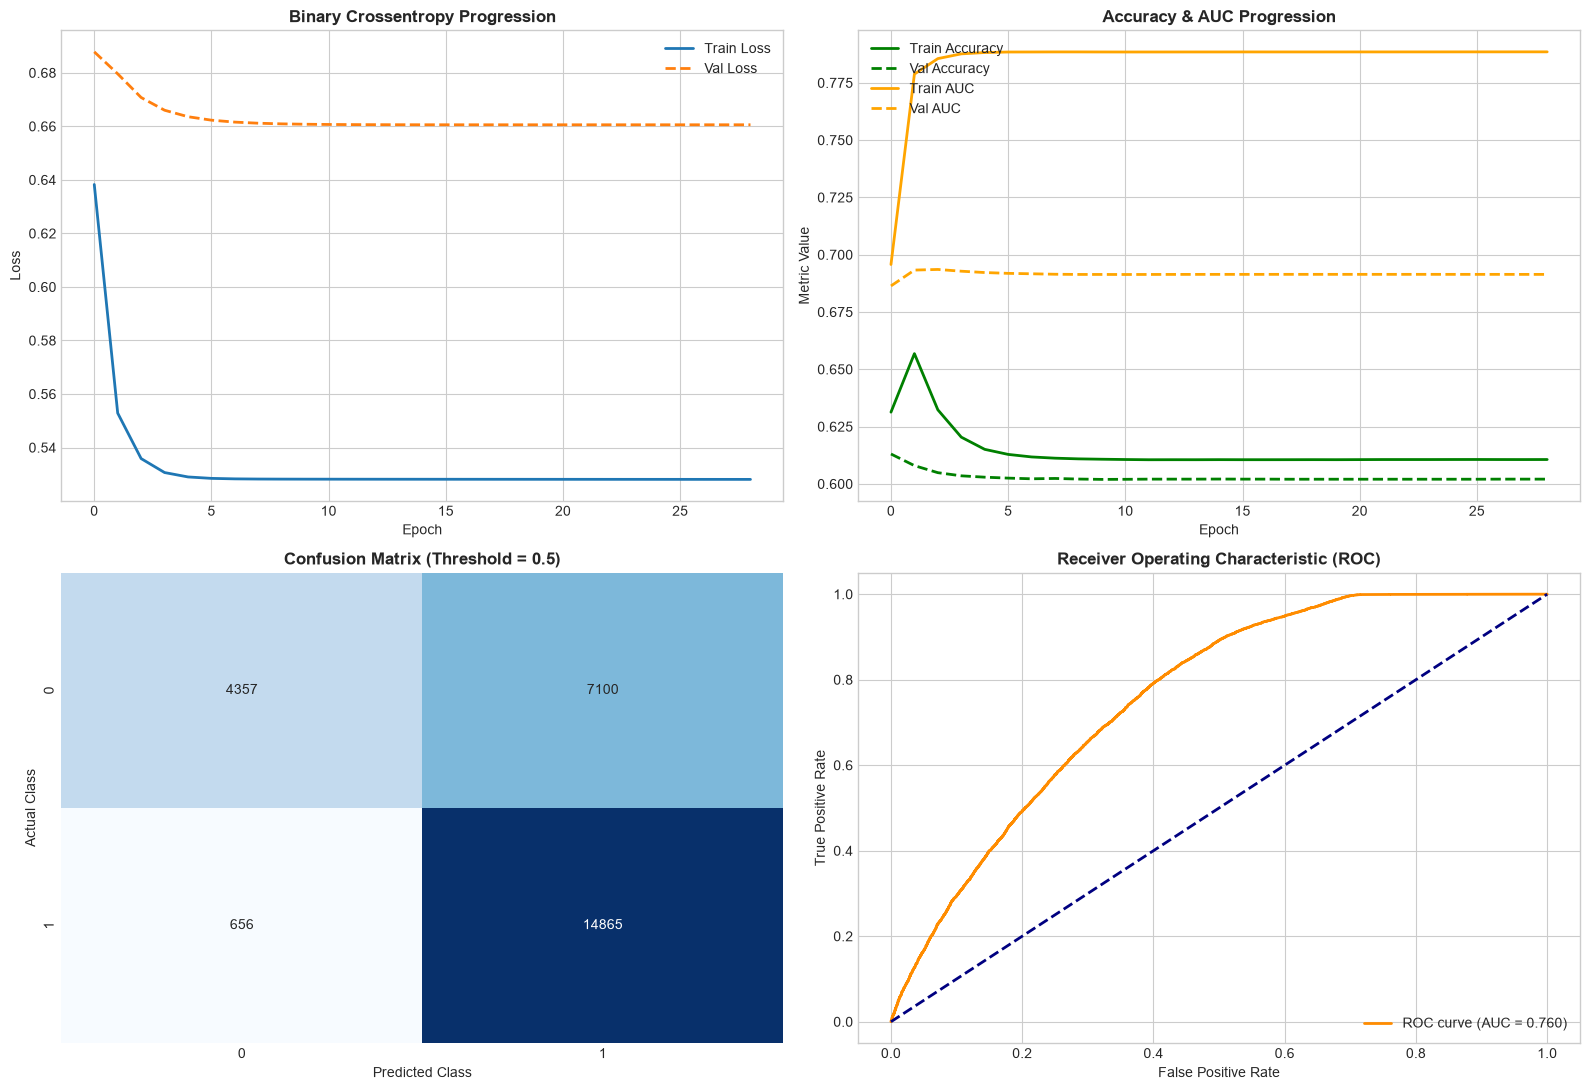

In [103]:
import matplotlib.pyplot as plt

print("X_test:", X_test.shape, "| y_test:", y_test.shape)

df_preds, df_metrics = model_base.evaluate(
    model=history.model,
    history=history,
    X_test=X_test,
    y_test=y_test,
)

In [104]:
model_base.print_weigths(model, X_test, X.columns)

                     Feature  Coefficient  Std Error      p-value  Significativo (p < 0.05)
             patadas_totales     0.213959   0.012211 0.000000e+00                      True
  desviaciones_leche_totales    -0.150974   0.155762 3.324130e-01                     False
         ordenios_con_lavado    -0.469916   0.174066 6.941244e-03                      True
            pct_primer_parto    -0.075137   0.018937 7.254494e-05                      True
                  pct_fresca     1.120642   0.030539 0.000000e+00                      True
                    pct_alta     1.038911   0.027917 0.000000e+00                      True
                    pct_baja     0.893158   0.025260 0.000000e+00                      True
               pct_extendida     0.594904   0.018735 0.000000e+00                      True
                 hubo_lavado     0.264113   0.075911 5.027948e-04                      True
       ordenios_otros_robots     0.205957   0.014921 0.000000e+00               